# 02 · EDA and CPCB benchmarking

**Purpose.** Compare AQI trends across the 7 cities over a 60-day winter window
(1 Nov to 30 Dec 2019), and benchmark Delhi's pollutant levels against the CPCB National Ambient
Air Quality Standards (NAAQS) for the same window and for the full 2015–2020 period.

**Inputs**
- `../data/city_day.csv`

**Outputs**
- `../results/city_trends_60_days.csv`
- `../results/delhi_vs_naaqs_60_days.csv`
- `../results/delhi_vs_naaqs_2015_2020.csv`
- `../results/figures/aqi_trends_60_days.png`
- `../results/figures/delhi_vs_naaqs.png`

## Configuration
Same values as the original `src/config.py`.

In [1]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path("../data/city_day.csv")
RESULTS_DIR = Path("../results")
FIG_DIR = RESULTS_DIR / "figures"

CITIES = ["Ahmedabad", "Bengaluru", "Chennai", "Delhi", "Hyderabad", "Lucknow", "Mumbai"]
AQI_SCALE_MAX = 500

NAAQS_24H = {"PM2.5": 60, "PM10": 100, "NO2": 80, "SO2": 80, "NH3": 400, "CO": 2, "O3": 100}

STUDY_WINDOW_DAYS = 60
WINDOW_START = pd.Timestamp("2019-11-01")
WINDOW_END = WINDOW_START + pd.Timedelta(days=STUDY_WINDOW_DAYS - 1)

AQI_BANDS = [(0, 50, "Good"), (51, 100, "Satisfactory"), (101, 200, "Moderate"),
             (201, 300, "Poor"), (301, 400, "Very Poor"), (401, 10_000, "Severe")]

In [2]:
import matplotlib.pyplot as plt

FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the raw data
This analysis uses the **raw** measurements (7 cities, AQI capped at 500), not the cleaned series
from notebook 01. Trend and exceedance statistics should count only days with an actual
measurement, not forward-filled values.

The AQI cap is the same data-quality rule as in notebook 01. Ahmedabad's implausible CO readings
push its reported AQI up to 2,049, and the AQI scale ends at 500.

In [3]:
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
raw = raw[raw["City"].isin(CITIES)].copy()
raw["AQI"] = raw["AQI"].clip(upper=AQI_SCALE_MAX)
print(f"Raw rows for the 7 study cities: {len(raw)}")

Raw rows for the 7 study cities: 14060


In [4]:
def window(df: pd.DataFrame) -> pd.DataFrame:
    return df[(df["Date"] >= WINDOW_START) & (df["Date"] <= WINDOW_END)]

w = window(raw)
print(f"Window {WINDOW_START:%d %b %Y} to {WINDOW_END:%d %b %Y}: {len(w)} city-days")

Window 01 Nov 2019 to 30 Dec 2019: 420 city-days


## 2. 60-day AQI trends across the 7 cities
Mean and maximum AQI per city over the window, plus the share of days rated *Poor or worse*
(AQI > 200). Ahmedabad's values are inflated by its suspect CO readings.

In [5]:
trends = (w.groupby("City")["AQI"]
           .agg(mean_aqi="mean", max_aqi="max", days_with_data="count")
           .round(1))
trends["pct_days_poor_or_worse"] = (w.assign(bad=w["AQI"] > 200)
                                     .groupby("City")["bad"].mean().mul(100).round(1))
trends = trends.sort_values("mean_aqi", ascending=False)
trends.to_csv(RESULTS_DIR / "city_trends_60_days.csv")
trends

,mean_aqi,max_aqi,days_with_data,pct_days_poor_or_worse
City,,,,
Delhi,346.4,500.0,60,90.0
Ahmedabad,334.8,500.0,60,80.0
Lucknow,309.8,455.0,60,88.3
Mumbai,159.7,283.0,60,21.7
Hyderabad,135.0,186.0,60,0.0
Chennai,101.0,294.0,60,11.7
Bengaluru,88.7,174.0,60,0.0


Daily AQI per city. Dashed lines mark the category boundaries (Satisfactory, Moderate, Poor,
Very Poor).

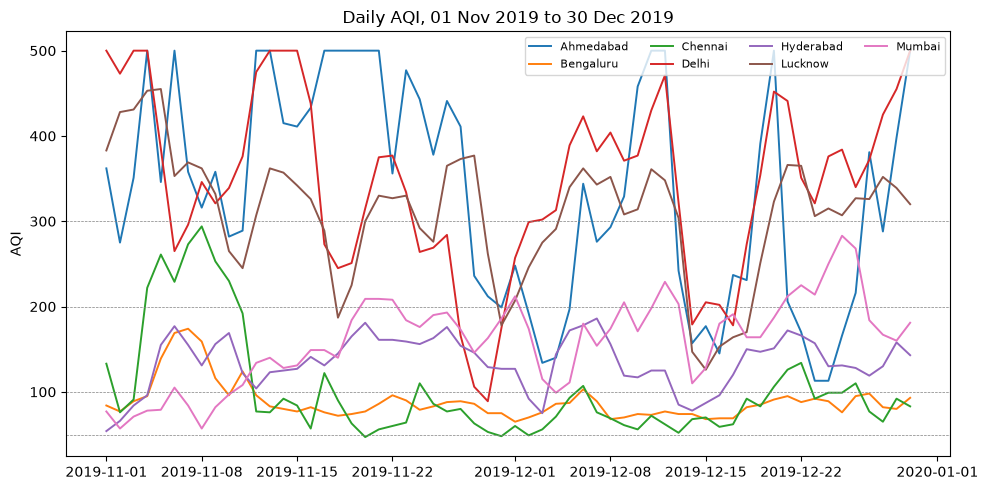

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for city in CITIES:
    s = w[w["City"] == city].set_index("Date")["AQI"]
    ax.plot(s.index, s.values, label=city, linewidth=1.4)
for lo, _, name in AQI_BANDS[1:5]:
    ax.axhline(lo - 1, color="grey", linewidth=0.5, linestyle="--")
ax.set_title(f"Daily AQI, {WINDOW_START:%d %b %Y} to {WINDOW_END:%d %b %Y}")
ax.set_ylabel("AQI")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "aqi_trends_60_days.png", dpi=150)
plt.show()

## 3. Delhi vs CPCB NAAQS limits
For each pollutant: mean daily concentration, ratio of the mean to the 24-hour NAAQS limit, and
share of days the daily mean exceeds the limit. Only days with a measurement are counted.

In [7]:
def delhi_vs_naaqs(df: pd.DataFrame) -> pd.DataFrame:
    d = df[df["City"] == "Delhi"]
    rows = []
    for pol, limit in NAAQS_24H.items():
        s = d[pol].dropna()
        if s.empty:
            continue
        rows.append({"pollutant": pol, "naaqs_limit": limit, "mean": round(s.mean(), 1),
                     "mean_to_limit_ratio": round(s.mean() / limit, 2),
                     "pct_days_exceeding": round((s > limit).mean() * 100, 1),
                     "days_with_data": len(s)})
    return pd.DataFrame(rows).sort_values("mean_to_limit_ratio", ascending=False)

### 3a. 60-day window (1 Nov to 30 Dec 2019)

In [8]:
delhi_window = delhi_vs_naaqs(window(raw))
delhi_window.to_csv(RESULTS_DIR / "delhi_vs_naaqs_60_days.csv", index=False)
delhi_window

,pollutant,naaqs_limit,mean,mean_to_limit_ratio,pct_days_exceeding,days_with_data
0,PM2.5,60,204.6,3.41,96.7,60
1,PM10,100,311.0,3.11,98.3,60
5,CO,2,1.7,0.86,31.7,60
2,NO2,80,55.2,0.69,6.7,60
6,O3,100,32.1,0.32,0.0,60
3,SO2,80,11.7,0.15,0.0,60
4,NH3,400,45.2,0.11,0.0,60


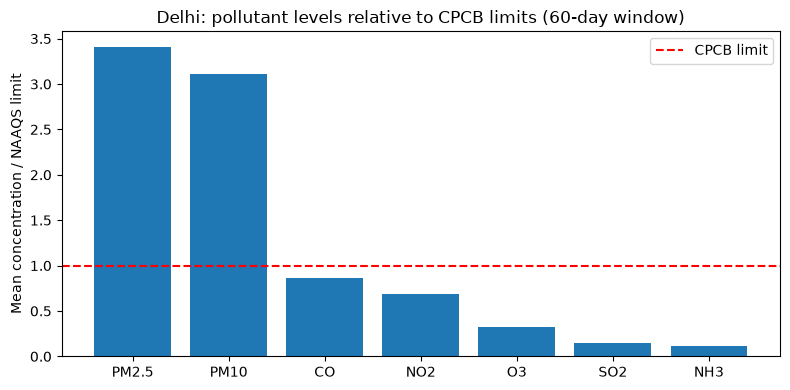

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(delhi_window["pollutant"], delhi_window["mean_to_limit_ratio"])
ax.axhline(1.0, color="red", linestyle="--", label="CPCB limit")
ax.set_ylabel("Mean concentration / NAAQS limit")
ax.set_title("Delhi: pollutant levels relative to CPCB limits (60-day window)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "delhi_vs_naaqs.png", dpi=150)
plt.show()

### 3b. Full period (2015–2020)

In [10]:
delhi_full = delhi_vs_naaqs(raw)
delhi_full.to_csv(RESULTS_DIR / "delhi_vs_naaqs_2015_2020.csv", index=False)
delhi_full

,pollutant,naaqs_limit,mean,mean_to_limit_ratio,pct_days_exceeding,days_with_data
1,PM10,100,232.8,2.33,85.9,1932
0,PM2.5,60,117.2,1.95,72.5,2007
5,CO,2,2.0,0.99,21.5,2009
2,NO2,80,50.8,0.63,10.2,2007
6,O3,100,51.3,0.51,5.6,1925
3,SO2,80,15.9,0.20,0.0,1899
4,NH3,400,42.0,0.10,0.0,2000


**Takeaway.** In the winter window, PM2.5 and PM10 average more than 3x their limits and exceed
them on almost every day. Every other pollutant averages below its limit, so particulate matter
drives Delhi's AQI. The full-period figures show the same pattern at lower levels.